<a href="https://colab.research.google.com/github/kes-bruh/Transfer-Learning-Fast-Food-Classification/blob/main/Fast_Food_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fast Food Image Classification - Transfer Learning
Dataset: `andrewsunanda/fast_food_image_classification` = Hugging Face, 10 classes.
Model: pretrained ResNet18: ImageNet. Two strategies are compared: frozen backbone and full fine-tuning.

In [ ]:
!pip install -q datasets torchvision lightning torchmetrics

## 1. Data: load, split, transforms, DataLoaders

In [ ]:
# ------------------------------------------------------------
# 1. Import
# ------------------------------------------------------------
import os
import torch
from collections import Counter
from datasets import load_dataset, DatasetDict
from torchvision import transforms
from torch.utils.data import DataLoader
from lightning.pytorch import seed_everything

# The HF token
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("kacin")
except Exception:
    pass

# ------------------------------------------------------------
# 2. Load fast_food_image_classification from Hugging Face
# ------------------------------------------------------------
# fixed starting point for reproducibility
SEED = 17
seed_everything(SEED, workers=True)

dataset = load_dataset("andrewsunanda/fast_food_image_classification", revision = "refs/convert/parquet")



print(dataset)

# ------------------------------------------------------------
# 3. Create a train/val/test split (70/15/15)
# ------------------------------------------------------------
# stratify_by_column keeps the class balance equal in every split
if "test" not in dataset:
    tmp = dataset["train"].train_test_split(test_size=0.3, seed=SEED, stratify_by_column="label")
    tmp2 = tmp["test"].train_test_split(test_size=0.5, seed=SEED, stratify_by_column="label")
    dataset = DatasetDict(train=tmp["train"], validation=tmp2["train"], test=tmp2["test"])
elif "validation" not in dataset:
    tmp = dataset["train"].train_test_split(test_size=0.15, seed=SEED, stratify_by_column="label")
    dataset = DatasetDict(train=tmp["train"], validation=tmp["test"], test=dataset["test"])

class_names = dataset["train"].features["label"].names
NUM_CLASSES = len(class_names)
print(class_names, NUM_CLASSES)
print({k: len(v) for k, v in dataset.items()})
print("Train images per class:",
      {class_names[k]: v for k, v in sorted(Counter(dataset["train"]["label"]).items())})

# ------------------------------------------------------------
# 4. Define transforms
# ------------------------------------------------------------
# ImageNet stats (pretrained model)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Training: augmentation, including RandomErasing.
# RandomErasing works on tensors, so it goes AFTER ToTensor/Normalize.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.2), ratio=(0.3, 3.3), value=0),
])

# Validation / test
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

def make_transform_batch(tf):
    # 3 channels
    def transform_batch(batch):
        return {
            "pixel_values": [tf(img.convert("RGB")) for img in batch["image"]],
            "label": batch["label"],
        }
    return transform_batch

def collate_fn(batch):
    imgs = torch.stack([x["pixel_values"] for x in batch])
    lbls = torch.tensor([x["label"] for x in batch])
    return imgs, lbls

# ------------------------------------------------------------
# 5. Create DataLoaders
# ------------------------------------------------------------
def make_loader(split, tf, shuffle=False):
    ds = dataset[split].with_transform(make_transform_batch(tf))
    return DataLoader(ds, batch_size=64, shuffle=shuffle, num_workers=2,
                      pin_memory=True, collate_fn=collate_fn)

train_loader = make_loader("train", train_transform, shuffle=True)
val_loader = make_loader("validation", eval_transform)
test_loader = make_loader("test", eval_transform)

# ------------------------------------------------------------
# 6. Quick check
# ------------------------------------------------------------
images, labels = next(iter(train_loader))
print(f"Images: {images.shape}, Labels: {labels.shape}")

INFO: Seed set to 17
INFO:lightning.fabric.utilities.seed:Seed set to 17


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 3000
    })
})
['Baked Potato', 'Burger', 'Crispy Chicken', 'Donut', 'Fries', 'Hot Dog', 'Pizza', 'Sandwich', 'Taco', 'Taquito'] 10
{'train': 2100, 'validation': 450, 'test': 450}
Train images per class: {'Baked Potato': 210, 'Burger': 210, 'Crispy Chicken': 210, 'Donut': 210, 'Fries': 210, 'Hot Dog': 210, 'Pizza': 210, 'Sandwich': 210, 'Taco': 210, 'Taquito': 210}
Images: torch.Size([64, 3, 224, 224]), Labels: torch.Size([64])


In [ ]:
import matplotlib.pyplot as plt

def show_images(tensors, labels, label_names, preds=None, n=8):
    """Show n images from a batch. With preds: green title = correct, red = wrong."""
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    n = min(n, len(tensors))
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.8))
    for i in range(n):
        img = torch.clamp(tensors[i].detach().cpu() * std + mean, 0, 1)   # undo normalization
        axes[i].imshow(img.permute(1, 2, 0).numpy())
        title, color = label_names[int(labels[i])], "black"
        if preds is not None:
            title += f"\n-> {label_names[int(preds[i])]}"
            color = "green" if int(preds[i]) == int(labels[i]) else "red"
        axes[i].set_title(title, fontsize=8, color=color)
        axes[i].axis("off")
    plt.tight_layout()
    plt.show()

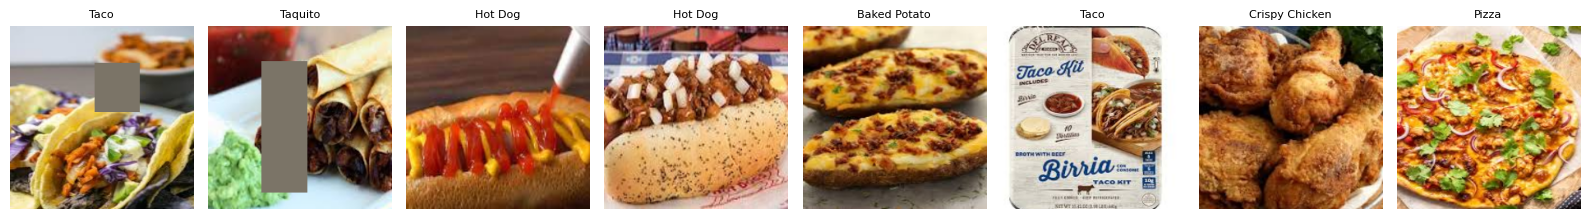

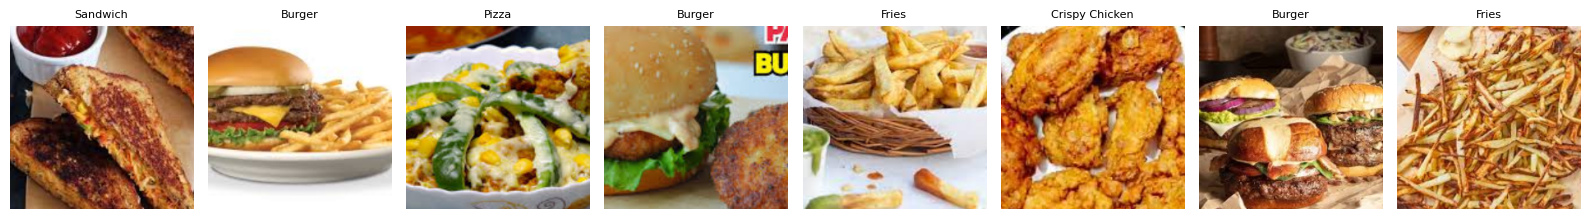

In [ ]:
# Augmented
x, y = next(iter(train_loader))
show_images(x, y, class_names)

# Clean validation
x, y = next(iter(val_loader))
show_images(x, y, class_names)

## 2. Model: pretrained ResNet18 (transfer learning / fine-tuning)

In [ ]:
# ------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from lightning.pytorch import LightningModule, Trainer
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint, LearningRateMonitor
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassPrecision, MulticlassRecall, MulticlassF1Score)

# ------------------------------------------------------------
# 3. Define Lightning Module
# ------------------------------------------------------------
class LitResNet18(LightningModule):
    def __init__(self, num_classes=10, lr=1e-3, freeze_backbone=False):
        super().__init__()
        self.save_hyperparameters()

        # pretrained ResNet18 backbone
        self.model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.model.fc = nn.Linear(self.model.fc.in_features, num_classes)

        # frozen backbone = feature extraction
        if freeze_backbone:
            for name, p in self.model.named_parameters():
                p.requires_grad = name.startswith("fc")

        # a separate set for train / val / test
        def make_metrics():
            return nn.ModuleDict({
                "acc": MulticlassAccuracy(num_classes=num_classes, average="micro"),
                "precision": MulticlassPrecision(num_classes=num_classes, average="macro"),
                "recall": MulticlassRecall(num_classes=num_classes, average="macro"),
                "f1": MulticlassF1Score(num_classes=num_classes, average="macro"),
            })
        self.train_m, self.val_m, self.test_m = make_metrics(), make_metrics(), make_metrics()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y)
        preds = torch.argmax(logits, dim=1)
        self.log(f"{stage}/loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        for name, metric in getattr(self, f"{stage}_m").items():
            metric.update(preds, y)
            self.log(f"{stage}/{name}", metric, on_step=False, on_epoch=True, prog_bar=(name == "acc"))
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self._shared_step(batch, "test")

    def configure_optimizers(self):
        params = [p for p in self.parameters() if p.requires_grad]
        optimizer = torch.optim.Adam(params, lr=self.hparams.lr)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.trainer.max_epochs)
        return {"optimizer": optimizer, "lr_scheduler": scheduler}

## 3. Training experiments

In [ ]:
# ------------------------------------------------------------
# 4-9. Loggers, callbacks, trainer, train
# ------------------------------------------------------------
results = {}

def run(name, freeze_backbone, lr, epochs=10):
    seed_everything(SEED, workers=True)
    model = LitResNet18(num_classes=NUM_CLASSES, lr=lr, freeze_backbone=freeze_backbone)

    logger = CSVLogger("logs", name=name)
    early_stop = EarlyStopping(monitor="val/acc", mode="max", patience=3, verbose=True)
    checkpoint = ModelCheckpoint(monitor="val/acc", mode="max", save_top_k=1,
                                 dirpath=f"checkpoints/{name}", filename="best",
                                 auto_insert_metric_name=False)
    lr_monitor = LearningRateMonitor(logging_interval="epoch")

    trainer = Trainer(
        max_epochs=epochs,
        accelerator="auto",
        devices=1,
        precision="16-mixed" if torch.cuda.is_available() else 32,
        logger=logger,
        callbacks=[early_stop, checkpoint, lr_monitor],
        log_every_n_steps=10,
    )
    trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)

    # test the best checkpoint NOT LAST EPOCH
    test = trainer.test(model, dataloaders=test_loader, ckpt_path="best")[0]

    results[name] = {
        "val_acc": float(checkpoint.best_model_score),
        "test_acc": test["test/acc"],
        "test_f1": test["test/f1"],
        "ckpt": checkpoint.best_model_path,
        "log_dir": logger.log_dir,
    }

In [ ]:
#A: transfer learning -frozen backbone
run("frozen_backbone", freeze_backbone=True, lr=1e-3)

INFO: Seed set to 17
INFO:lightning.fabric.utilities.seed:Seed set to 17


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ ResNet     │ 11.2 M │ train │     0 │
│ 1 │ train_m │ ModuleDict │      0 │ train │     0 │
│ 2 │ val_m   │ ModuleDict │      0 │ train │     0 │
│ 3 │ test_m  │ ModuleDict │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 5.1 K                                                                                            
Non-trainable params: 11.2 M                                                                                       
Total params: 11.2 M                                                                                               
Total estimated model params size (MB): 44.727                                                                     
Modules in train mode: 83                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: Metric val/acc improved. New best score: 0.573
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved. New best score: 0.573
INFO: Metric val/acc improved by 0.131 >= min_delta = 0.0. New best score: 0.704
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.131 >= min_delta = 0.0. New best score: 0.704
INFO: Metric val/acc improved by 0.038 >= min_delta = 0.0. New best score: 0.742
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.038 >= min_delta = 0.0. New best score: 0.742
INFO: Metric val/acc improved by 0.018 >= min_delta = 0.0. New best score: 0.760
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.018 >= min_delta = 0.0. New best score: 0.760
INFO: Metric val/acc improved by 0.007 >= min_delta = 0.0. New best score: 0.767
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.007 >= min_delta = 0.0. New best score: 0.767
INFO: Metric val/acc improved by 0.0

INFO: Restoring states from the checkpoint path at /content/checkpoints/frozen_backbone/best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/checkpoints/frozen_backbone/best.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/checkpoints/frozen_backbone/best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at /content/checkpoints/frozen_backbone/best.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/acc          │    0.7799999713897705     │
│          test/f1          │    0.7801411151885986     │
│         test/loss         │    0.7850970029830933     │
│      test/precision       │    0.7927558422088623     │
│        test/recall        │    0.7800000309944153     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
#B: fine tuning
run("fine_tune_all", freeze_backbone=False, lr=1e-4)

INFO: Seed set to 17
INFO:lightning.fabric.utilities.seed:Seed set to 17
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - C

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ ResNet     │ 11.2 M │ train │     0 │
│ 1 │ train_m │ ModuleDict │      0 │ train │     0 │
│ 2 │ val_m   │ ModuleDict │      0 │ train │     0 │
│ 3 │ test_m  │ ModuleDict │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 11.2 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 11.2 M                                                                                               
Total estimated model params size (MB): 44.727                                                                     
Modules in train mode: 83                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: Metric val/acc improved. New best score: 0.822
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved. New best score: 0.822
INFO: Metric val/acc improved by 0.031 >= min_delta = 0.0. New best score: 0.853
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.031 >= min_delta = 0.0. New best score: 0.853
INFO: Metric val/acc improved by 0.004 >= min_delta = 0.0. New best score: 0.858
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.004 >= min_delta = 0.0. New best score: 0.858
INFO: Metric val/acc improved by 0.020 >= min_delta = 0.0. New best score: 0.878
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.020 >= min_delta = 0.0. New best score: 0.878
INFO: Metric val/acc improved by 0.016 >= min_delta = 0.0. New best score: 0.893
INFO:lightning.pytorch.callbacks.early_stopping:Metric val/acc improved by 0.016 >= min_delta = 0.0. New best score: 0.893
INFO: Metric val/acc improved by 0.0

INFO: Restoring states from the checkpoint path at /content/checkpoints/fine_tune_all/best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/checkpoints/fine_tune_all/best.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/checkpoints/fine_tune_all/best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at /content/checkpoints/fine_tune_all/best.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/acc          │     0.902222216129303     │
│          test/f1          │     0.902021586894989     │
│         test/loss         │    0.33534353971481323    │
│      test/precision       │    0.9026651978492737     │
│        test/recall        │     0.902222216129303     │
└───────────────────────────┴───────────────────────────┘

## 4. Results

In [ ]:
# Results table
pd.DataFrame(results).T[["val_acc", "test_acc", "test_f1"]].astype(float).round(3)

,val_acc,test_acc,test_f1
frozen_backbone,0.782,0.780,0.780
fine_tune_all,0.898,0.902,0.902


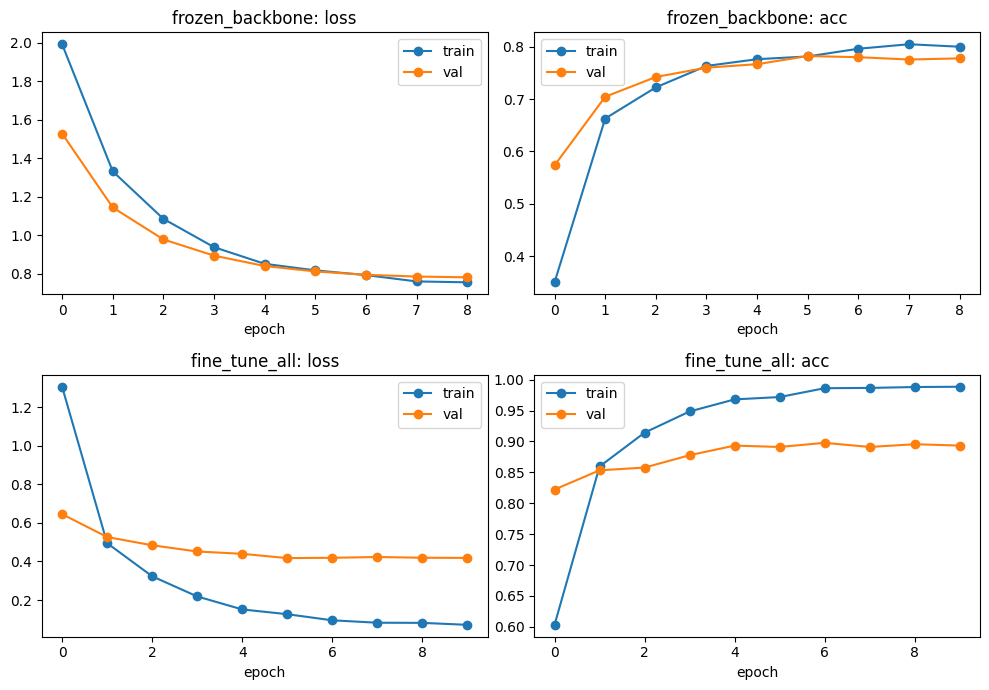

In [ ]:
# Training / validation curves for each experiment.Learned from this https://www.youtube.com/watch?v=KFMs_ZZNgmo$0
fig, axes = plt.subplots(len(results), 2, figsize=(10, 3.5 * len(results)), squeeze=False)
for row, (name, r) in zip(axes, results.items()):
    df = pd.read_csv(f"{r['log_dir']}/metrics.csv").groupby("epoch").mean(numeric_only=True)
    for ax, metric in zip(row, ["loss", "acc"]):
        ax.plot(df.index, df[f"train/{metric}"], marker="o", label="train")
        ax.plot(df.index, df[f"val/{metric}"], marker="o", label="val")
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("epoch")
        ax.legend()
plt.tight_layout()
plt.show()

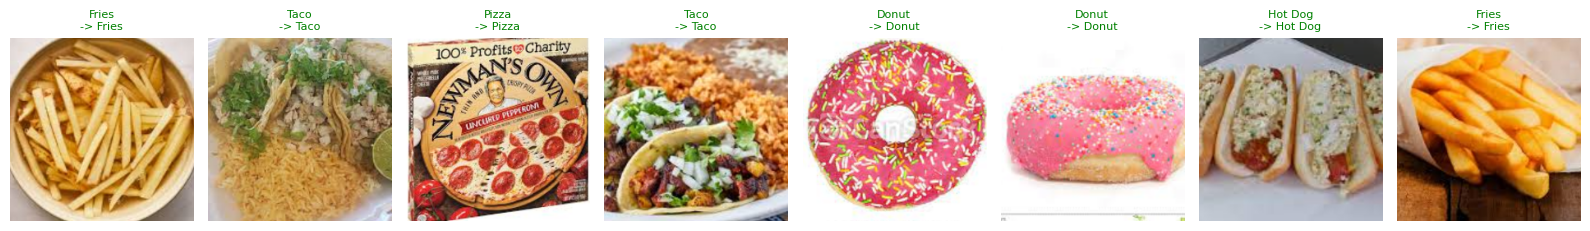

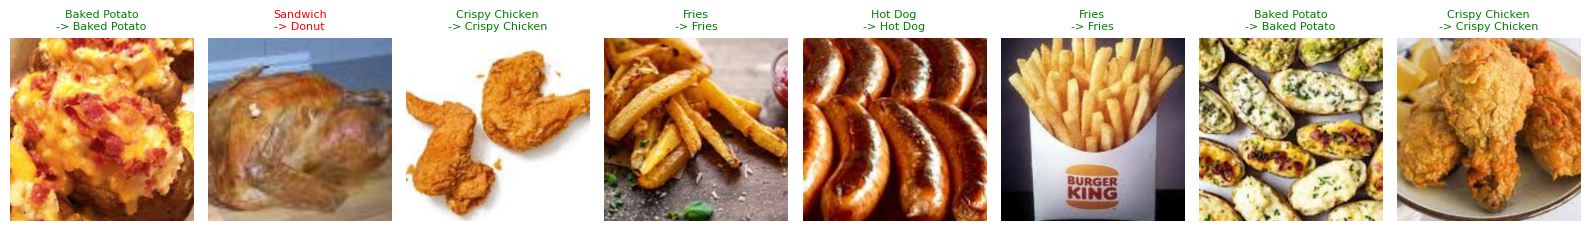

In [ ]:
# Example predictions on test images : green = correct, red = wrong
x, y = next(iter(test_loader))
with torch.no_grad():
    preds = best_model(x.to(device)).argmax(1).cpu()

show_images(x[:8], y[:8], class_names, preds[:8])
show_images(x[8:16], y[8:16], class_names, preds[8:16])